--> Thiet bi dang su dung: cpu

--- BANG THONG KE SO LUONG MAU FER2013 ---
          Train  Test  Total
angry      3995   958   4953
disgust     436   111    547
fear       4097  1024   5121
happy      7215  1774   8989
neutral    4965  1233   6198
sad        4830  1247   6077
surprise   3171   831   4002


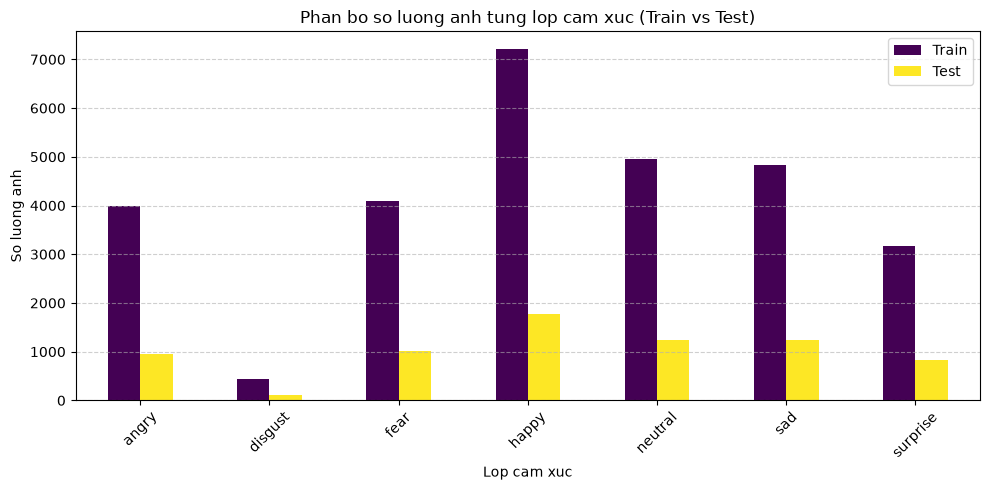

--> Da luu bieu do vao results/plots/dataset_distribution.png thanh cong!


In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# 1. Kiem tra thiet bi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Thiet bi dang su dung: {device}")
if torch.cuda.is_available():
    print(f"--> GPU: {torch.cuda.get_device_name(0)}")

# 2. Duong dan du lieu
DATA_DIR = r"../data/raw"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

# 3. Thong ke so luong mau
train_counts = {c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in CLASSES}
test_counts = {c: len(os.listdir(os.path.join(TEST_DIR, c))) for c in CLASSES}

df_stats = pd.DataFrame({"Train": train_counts, "Test": test_counts})
df_stats["Total"] = df_stats["Train"] + df_stats["Test"]
print("\n--- BANG THONG KE SO LUONG MAU FER2013 ---")
print(df_stats)

# 4. Ve bieu do phan bo nhan
os.makedirs("../results/plots", exist_ok=True)
ax = df_stats[["Train", "Test"]].plot(kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("Phan bo so luong anh tung lop cam xuc (Train vs Test)")
plt.xlabel("Lop cam xuc")
plt.ylabel("So luong anh")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("../results/plots/dataset_distribution.png", dpi=300)
plt.show()
print("--> Da luu bieu do vao results/plots/dataset_distribution.png thanh cong!")

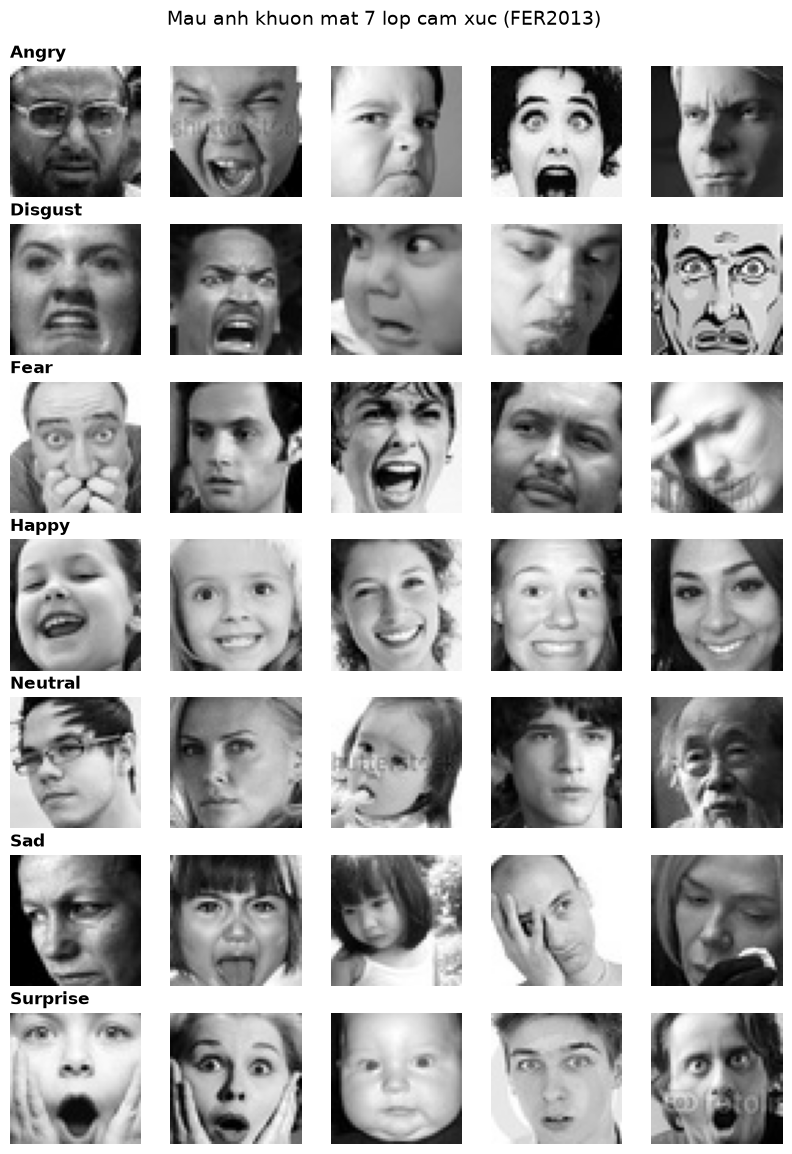

--> Da luu anh mau vao results/plots/sample_faces.png!


In [2]:
import random
from PIL import Image

# Thiết lập lưới hiển thị 7 dòng (7 nhãn), mỗi dòng 5 ảnh ngẫu nhiên
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(10, 14))

for row_idx, cls in enumerate(CLASSES):
    cls_folder = os.path.join(TRAIN_DIR, cls)
    sample_images = random.sample(os.listdir(cls_folder), 5)
    
    for col_idx, img_name in enumerate(sample_images):
        img_path = os.path.join(cls_folder, img_name)
        img = Image.open(img_path)
        
        ax = axes[row_idx, col_idx]
        ax.imshow(img, cmap="gray")
        ax.axis("off")
        
        if col_idx == 0:
            ax.set_title(cls.capitalize(), fontsize=12, fontweight="bold", loc="left")

plt.suptitle("Mau anh khuon mat 7 lop cam xuc (FER2013)", fontsize=14, y=0.92)
plt.savefig("../results/plots/sample_faces.png", dpi=300, bbox_inches="tight")
plt.show()
print("--> Da luu anh mau vao results/plots/sample_faces.png!")